HYDROSTATIC GUIDEWAY LOAD ESTIMATOR ---- Inputs

Table length (mm):  700
Table breadth (mm):  400
Table height (mm):  70
Pocket margin in x-direction (mm):  30
Pocket margin in y-direction (mm):  30
Acceleration due to gravity (m/s²):  10
Mass of table (kg):  50
Table CG x-coordinate (mm):  50
Table CG y-coordinate (mm):  50
Table CG z-coordinate (mm):  70
Lead screw x-coordinate (mm):  50
Lead screw y-coordinate (mm):  50
Lead screw z-coordinate (mm):  10
Acceleration in x-direction (m/s²):  7
Acceleration in y-direction (m/s²):  0
Number of external loads:  2

Load 1
Mass (kg):  10
x-coordinate (mm):  200
y-coordinate (mm):  200
z-coordinate (mm):  80

Load 2
Mass (kg):  30
x-coordinate (mm):  150
y-coordinate (mm):  150
z-coordinate (mm):  90


HYDROSTATIC GUIDEWAY LOAD ESTIMATOR



Table length (mm):  700
Table breadth (mm):  400
Table height (mm):  70
Pocket margin in x-direction (mm):  30
Pocket margin in y-direction (mm):  30
Acceleration due to gravity (m/s²):  10
Mass of table (kg):  50
Table CG x-coordinate (mm):  50
Table CG y-coordinate (mm):  50
Table CG z-coordinate (mm):  70
Lead screw x-coordinate (mm):  50
Lead screw y-coordinate (mm):  50
Lead screw z-coordinate (mm):  10
Acceleration in x-direction (m/s²):  7
Acceleration in y-direction (m/s²):  0
Number of external loads:  2



Load 1


Mass (kg):  10
x-coordinate (mm):  200
y-coordinate (mm):  200
z-coordinate (mm):  80



Load 2


Mass (kg):  30
x-coordinate (mm):  150
y-coordinate (mm):  150
z-coordinate (mm):  90



========== RESULTS ==========
Total mass : 90.000 kg
Total weight : 900.000 N

CG = (100.00, 100.00, 77.78) mm
Effective height h = 67.78 mm

Pocket reactions (N)
N1 = 157.56
N2 = 288.85
N3 = 160.09
N4 = 293.50

Sum of reactions = 900.00 N


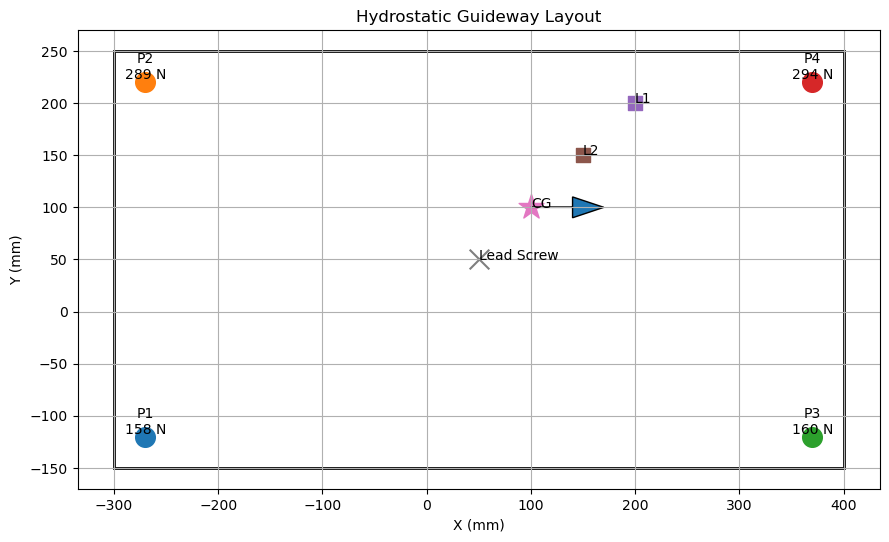

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ==========================================
# INPUTS
# ==========================================
print("\nHYDROSTATIC GUIDEWAY LOAD ESTIMATOR\n")

# Table dimensions
length = float(input("Table length (mm): "))
breadth = float(input("Table breadth (mm): "))
height = float(input("Table height (mm): "))
margin_x = float(input("Pocket margin in x-direction (mm): "))
margin_y = float(input("Pocket margin in y-direction (mm): "))

# Gravity
g = float(input("Acceleration due to gravity (m/s²): "))

# Table properties
m_table = float(input("Mass of table (kg): "))
x_table = float(input("Table CG x-coordinate (mm): "))
y_table = float(input("Table CG y-coordinate (mm): "))
z_table = float(input("Table CG z-coordinate (mm): "))

# Lead screw location
x_ls = float(input("Lead screw x-coordinate (mm): "))
y_ls = float(input("Lead screw y-coordinate (mm): "))
z_ls = float(input("Lead screw z-coordinate (mm): "))

# Accelerations
a_x = float(input("Acceleration in x-direction (m/s²): "))
a_y = float(input("Acceleration in y-direction (m/s²): "))

# ==========================================
# LOAD INPUTS
# ==========================================
total_mass = m_table
sum_mx = m_table * x_table
sum_my = m_table * y_table
sum_mz = m_table * z_table

load_x, load_y = [], []

n = int(input("Number of external loads: "))

for i in range(n):
    print(f"\nLoad {i+1}")

    m = float(input("Mass (kg): "))
    x = float(input("x-coordinate (mm): "))
    y = float(input("y-coordinate (mm): "))
    z = float(input("z-coordinate (mm): "))

    total_mass += m
    sum_mx += m * x
    sum_my += m * y
    sum_mz += m * z

    load_x.append(x)
    load_y.append(y)

# ==========================================
# COMBINED CG
# ==========================================
X = sum_mx / total_mass
Y = sum_my / total_mass
Z = sum_mz / total_mass

Total_W = total_mass * g
h = Z - z_ls

# ==========================================
# POCKET LOCATIONS
# ==========================================
x_b = x_table - length / 2 + margin_x
x_f = x_table + length / 2 - margin_x
y_r = y_table - breadth / 2 + margin_y
y_l = y_table + breadth / 2 - margin_y

xp_span = length - 2 * margin_x
yp_span = breadth - 2 * margin_y

b2c = X - x_b
f2c = x_f - X
r2c = Y - y_r
l2c = y_l - Y

# ==========================================
# REACTIONS
# ==========================================
tol = 1e-9

if abs(a_x) < tol and abs(a_y) < tol:

    N1 = Total_W * f2c * l2c / (xp_span * yp_span)
    N2 = Total_W * f2c * r2c / (xp_span * yp_span)
    N3 = Total_W * b2c * l2c / (xp_span * yp_span)
    N4 = Total_W * b2c * r2c / (xp_span * yp_span)

elif abs(a_x) > tol and abs(a_y) < tol:

    My = total_mass * a_x * h

    N1 = l2c * (Total_W * f2c + My) / (xp_span * yp_span)
    N2 = r2c * (Total_W * f2c + My) / (xp_span * yp_span)
    N3 = l2c * (Total_W * b2c - My) / (xp_span * yp_span)
    N4 = r2c * (Total_W * b2c - My) / (xp_span * yp_span)

elif abs(a_x) < tol and abs(a_y) > tol:

    Mx = total_mass * a_y * h

    N1 = f2c * (Total_W * l2c + Mx) / (xp_span * yp_span)
    N2 = f2c * (Total_W * r2c - Mx) / (xp_span * yp_span)
    N3 = b2c * (Total_W * l2c + Mx) / (xp_span * yp_span)
    N4 = b2c * (Total_W * r2c - Mx) / (xp_span * yp_span)

else:
    print("\nSimultaneous accelerations detected.")
    print("Pocket reactions cannot be uniquely determined from statics.")
    exit()

# ==========================================
# OUTPUTS
# ==========================================
print("\n========== RESULTS ==========")

print(f"Total mass : {total_mass:.3f} kg")
print(f"Total weight : {Total_W:.3f} N")

print(f"\nCG = ({X:.2f}, {Y:.2f}, {Z:.2f}) mm")
print(f"Effective height h = {h:.2f} mm")

print("\nPocket reactions (N)")
print(f"N1 = {N1:.2f}")
print(f"N2 = {N2:.2f}")
print(f"N3 = {N3:.2f}")
print(f"N4 = {N4:.2f}")

print(f"\nSum of reactions = {N1+N2+N3+N4:.2f} N")

if min(N1, N2, N3, N4) < 0:
    print("\nWARNING: One or more pockets have negative reactions.")

# ==========================================
# VISUALISATION
# ==========================================
fig, ax = plt.subplots(figsize=(9, 7))

# Table boundary
table_x = x_table - length / 2
table_y = y_table - breadth / 2

rect = patches.Rectangle(
    (table_x, table_y),
    length,
    breadth,
    fill=False,
    linewidth=2
)
ax.add_patch(rect)

# Pockets
px = [x_b, x_b, x_f, x_f]
py = [y_r, y_l, y_r, y_l]
labels = ["P1", "P2", "P3", "P4"]
forces = [N1, N2, N3, N4]

for x, y, p, f in zip(px, py, labels, forces):
    ax.scatter(x, y, s=200)
    ax.text(x, y,
            f"{p}\n{f:.0f} N",
            ha="center",
            va="bottom")

# External loads
for i, (x, y) in enumerate(zip(load_x, load_y)):
    ax.scatter(x, y, marker="s", s=100)
    ax.text(x, y, f"L{i+1}")

# Combined CG
ax.scatter(X, Y, marker="*", s=350)
ax.text(X, Y, "CG")

# Lead screw
ax.scatter(x_ls, y_ls, marker="x", s=200)
ax.text(x_ls, y_ls, "Lead Screw")

# Acceleration arrows
scale = 10

if abs(a_x) > tol:
    ax.arrow(X, Y,
             scale * a_x, 0,
             head_width=20,
             length_includes_head=True)

if abs(a_y) > tol:
    ax.arrow(X, Y,
             0, scale * a_y,
             head_width=20,
             length_includes_head=True)

# Formatting
ax.set_aspect("equal")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_title("Hydrostatic Guideway Layout")
ax.grid(True)

plt.tight_layout()
plt.savefig("Hydrostatic_Guideway_Layout.png", dpi=300)
plt.show()